# Lab 11.3: A Shortcut Hunt in Two Hospitals

Chapter 11, Where the Network Looks. A laboratory version of the chapter's case study. Two hospitals send images; one marks its images with a corner token and also sees most of the positive cases. You train one network on those confounded data and one on clean data, compare their performance inside and outside the hospitals, find the shortcut with Expected Gradients, confirm it with interventions, compare baselines, and run a sanity check. **Synthetic images, not a medical model.** Run the cells in order; one optional cell at the end invites an edit.

In [1]:
P_MARK_POS, P_MARK_NEG = 0.9, 0.1   # chance that a positive / negative training image carries the token
# Optional edit: try 0.7 and 0.3, then rerun all cells.

In [2]:
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from sklearn.metrics import roc_auc_score
torch.set_num_threads(4)
print("numpy", np.__version__, "| torch", torch.__version__)

S = 32
yy, xx = np.mgrid[0:S, 0:S]
BODY = ((xx - 15.5) / 14.5) ** 2 + ((yy - 18) / 15) ** 2 < 1
LUNGS = (((xx - 9.5) / 4.8) ** 2 + ((yy - 17) / 9) ** 2 < 1) | (((xx - 21.5) / 4.8) ** 2 + ((yy - 17) / 9) ** 2 < 1)
MARK = np.zeros((S, S), bool); MARK[2:7, 2:4] = True; MARK[5:7, 2:6] = True   # the L-shaped token


def make_images(n, p_pos, p_mark_pos, p_mark_neg, rng, amp=0.22):
    """Synthetic radiograph-like images. Returns images, labels, token flags, opacity masks.
    p_mark_pos / p_mark_neg: chance that a positive / negative image carries the token."""
    X = np.zeros((n, S, S), np.float32); y = (rng.random(n) < p_pos).astype(np.float32)
    m = np.where(y == 1, rng.random(n) < p_mark_pos, rng.random(n) < p_mark_neg)
    les = np.zeros((n, S, S), bool)
    lung_pix = np.argwhere(LUNGS & (yy > 11) & (yy < 24))
    for i in range(n):
        img = np.where(BODY, 0.62, 0.05) - np.where(LUNGS, 0.36, 0.0)
        img = img + gaussian_filter(rng.normal(0, 0.18, (S, S)), 3) + 0.05 * (rng.random() - 0.5)
        if y[i] == 1:
            cy, cx = lung_pix[rng.integers(len(lung_pix))]
            blob = np.exp(-((yy - cy) ** 2 + (xx - cx) ** 2) / (2 * 2.2 ** 2))
            img = img + amp * blob * LUNGS
            les[i] = blob > 0.3
        if m[i]:
            img = np.where(MARK, 0.95, img)
        X[i] = np.clip(img + rng.normal(0, 0.04, (S, S)), 0, 1)
    return X, y, m, les


class Net(nn.Module):
    def __init__(s):
        super().__init__()
        s.c1 = nn.Conv2d(1, 8, 3, padding=1); s.c2 = nn.Conv2d(8, 16, 3, padding=1)
        s.c3 = nn.Conv2d(16, 16, 3, padding=1); s.fc = nn.Linear(16, 1)
    def features(s, x):
        x = F.max_pool2d(F.relu(s.c1(x)), 2); x = F.max_pool2d(F.relu(s.c2(x)), 2)
        return F.relu(s.c3(x))
    def forward(s, x):
        return s.fc(s.features(x).mean((2, 3))).squeeze(-1)      # a logit


def train(X, y, seed=0, epochs=25):
    torch.manual_seed(seed); net = Net(); opt = torch.optim.Adam(net.parameters(), 3e-3)
    Xt, yt = torch.tensor(X[:, None]), torch.tensor(y); g = torch.Generator().manual_seed(seed)
    for _ in range(epochs):
        for idx in torch.randperm(len(X), generator=g).split(64):
            opt.zero_grad(); F.binary_cross_entropy_with_logits(net(Xt[idx]), yt[idx]).backward(); opt.step()
    return net.eval()


def predict(net, X):
    with torch.no_grad():
        return torch.sigmoid(net(torch.tensor(X[:, None]))).numpy()


def logit(net, x):
    with torch.no_grad():
        return net(torch.tensor(np.asarray(x, np.float32)[None, None])).item()


numpy 2.2.6 | torch 2.6.0


In [3]:
def _t(x):
    return torch.tensor(np.asarray(x, np.float32)[None, None])

def gradient(net, x):
    xt = _t(x).requires_grad_(True); net(xt).sum().backward(); return xt.grad[0, 0].numpy()

def grad_x_input(net, x):
    return gradient(net, x) * x

def smoothgrad(net, x, sigma=0.15, n=50, seed=0):
    rng = np.random.default_rng(seed)
    return np.mean([gradient(net, x + rng.normal(0, sigma, x.shape).astype(np.float32)) for _ in range(n)], 0)

def integrated_gradients(net, x, base=None, steps=64):
    base = np.zeros_like(x) if base is None else base
    alphas = (np.arange(steps) + 0.5) / steps                          # midpoint rule
    path = np.stack([base + a * (x - base) for a in alphas]).astype(np.float32)
    pt = torch.tensor(path[:, None]).requires_grad_(True); net(pt).sum().backward()
    return (x - base) * pt.grad[:, 0].numpy().mean(0)

def expected_gradients(net, x, refs, n=200, seed=0):
    rng = np.random.default_rng(seed)
    r = refs[rng.integers(len(refs), size=n)]; a = rng.random(n)[:, None, None]
    pt = torch.tensor((r + a * (x - r)).astype(np.float32)[:, None]).requires_grad_(True); net(pt).sum().backward()
    return ((x - r) * pt.grad[:, 0].numpy()).mean(0)

def gradcam(net, x):
    A = net.features(_t(x)); A.retain_grad(); net.fc(A.mean((2, 3))).sum().backward()
    w = A.grad[0].mean((1, 2)); cam = F.relu((w[:, None, None] * A[0]).sum(0))
    return F.interpolate(cam[None, None], size=(S, S), mode="bilinear", align_corners=False)[0, 0].detach().numpy()

def occlusion(net, x, size=4, stride=2):
    fill = x.mean(); base = logit(net, x); heat = np.zeros_like(x); cnt = np.zeros_like(x)
    for r in range(0, S - size + 1, stride):
        for c in range(0, S - size + 1, stride):
            z = x.copy(); z[r:r + size, c:c + size] = fill
            heat[r:r + size, c:c + size] += base - logit(net, z); cnt[r:r + size, c:c + size] += 1
    return heat / np.maximum(cnt, 1)

class GuidedReLU(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x):
        ctx.save_for_backward(x); return x.clamp(min=0)
    @staticmethod
    def backward(ctx, g):
        x, = ctx.saved_tensors; return g * (x > 0) * (g > 0)

def guided_backprop(net, x):
    xt = _t(x).requires_grad_(True); r = GuidedReLU.apply
    h = F.max_pool2d(r(net.c1(xt)), 2); h = F.max_pool2d(r(net.c2(h)), 2); h = r(net.c3(h))
    net.fc(h.mean((2, 3))).sum().backward(); return xt.grad[0, 0].numpy()

def shares(a, lesion):
    """Share of total |attribution| on the token and on the opacity."""
    a = np.abs(a); a = a / (a.sum() + 1e-12); return a[MARK].sum(), a[lesion].sum()

def show(ax, a, title, lesion=None, cmap="magma"):
    ax.imshow(a, cmap=cmap); ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
    if lesion is not None:
        ax.contour(lesion, levels=[0.5], colors=["cyan"], linewidths=1, linestyles="--")


## Part A. Two hospitals, two networks

In [4]:
rng = np.random.default_rng(1)
Xc, yc, mc, _ = make_images(3000, 0.5, P_MARK_POS, P_MARK_NEG, rng)   # confounded training data
Xk, yk, mk, _ = make_images(3000, 0.5, 0.5, 0.5, rng)                 # clean training data
Xi, yi, mi, _ = make_images(1000, 0.5, P_MARK_POS, P_MARK_NEG, rng)   # internal test (same hospitals)
Xe, ye, me, le = make_images(1000, 0.5, 0.5, 0.5, rng)                # external test (token independent)
NC, NK = train(Xc, yc), train(Xk, yk)
for name, n in (('confounded', NC), ('clean', NK)):
    print(f'{name:10s} internal AUROC {roc_auc_score(yi, predict(n, Xi)):.3f}   external AUROC {roc_auc_score(ye, predict(n, Xe)):.3f}')   # Checkpoint 1

confounded internal AUROC 0.978   external AUROC 0.730
clean      internal AUROC 0.960   external AUROC 0.969


## Part B. Where does each network look?

Expected Gradients with 200 healthy training images as baselines, the method of the case study. We average over 30 positive external images that carry the token. The token covers 1.4 percent of the image.

confounded mean share on token 0.319   on opacity 0.177


clean      mean share on token 0.012   on opacity 0.309


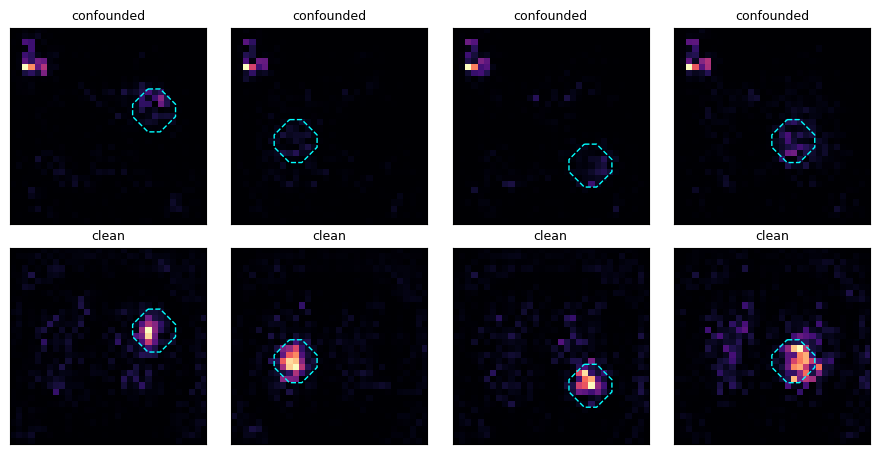

In [5]:
HEALTHY = Xk[yk == 0]
idx = np.where((ye == 1) & me)[0][:30]
for name, n in (('confounded', NC), ('clean', NK)):
    s = np.array([shares(expected_gradients(n, Xe[i], HEALTHY), le[i]) for i in idx])
    print(f'{name:10s} mean share on token {s[:,0].mean():.3f}   on opacity {s[:,1].mean():.3f}')   # Checkpoint 2
fig, axes = plt.subplots(2, 4, figsize=(9, 4.6))
for c, i in enumerate(idx[:4]):
    for r, (name, n) in enumerate((('confounded', NC), ('clean', NK))):
        show(axes[r, c], np.abs(expected_gradients(n, Xe[i], HEALTHY)), name, le[i])
plt.tight_layout(); plt.show()

## Part C. Interventions

A map is a hypothesis. Test it: add the token to healthy images without one, and paint it out of positive images that have one.

In [6]:
neg = Xe[(ye == 0) & ~me]; neg_tok = np.where(MARK, 0.95, neg).astype(np.float32)
pos_tok = Xe[(ye == 1) & me]; pos_clean = pos_tok.copy()
fill = np.random.default_rng(7).normal(0.05, 0.04, pos_clean.shape).clip(0, 1)   # background value with noise
pos_clean[:, MARK] = fill[:, MARK]
for name, n in (('confounded', NC), ('clean', NK)):
    print(f'{name:10s} healthy {predict(n, neg).mean():.3f} -> +token {predict(n, neg_tok).mean():.3f} | '
          f'positive {predict(n, pos_tok).mean():.3f} -> token removed {predict(n, pos_clean).mean():.3f}')   # Checkpoint 3
print('images:', len(neg), 'healthy,', len(pos_tok), 'positive with token')

confounded healthy 0.028 -> +token 0.756 | positive 0.919 -> token removed 0.124
clean      healthy 0.325 -> +token 0.303 | positive 0.854 -> token removed 0.864
images: 246 healthy, 250 positive with token


## Part D. The baseline is part of the question

Integrated Gradients for one positive image of the clean network, from four baselines. Look at the model's probability for each baseline before reading the maps.

black            p(baseline) 0.984   opacity share 0.144
blurred          p(baseline) 1.000   opacity share 0.016
noise            p(baseline) 1.000   opacity share 0.039
average healthy  p(baseline) 0.137   opacity share 0.408


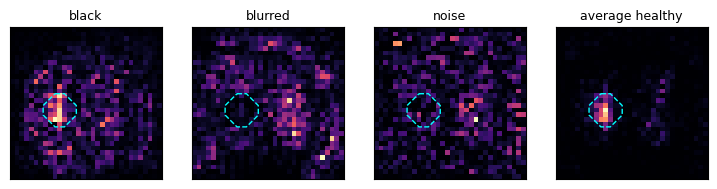

In [7]:
i = np.where((ye == 1) & ~me)[0][0]; x = Xe[i]
bases = {'black': np.zeros_like(x), 'blurred': gaussian_filter(x, 4).astype(np.float32),
         'noise': np.random.default_rng(5).random(x.shape).astype(np.float32), 'average healthy': HEALTHY.mean(0).astype(np.float32)}
fig, axes = plt.subplots(1, 4, figsize=(9, 2.6))
for ax, (k, b) in zip(axes, bases.items()):
    a = integrated_gradients(NK, x, base=b); p = 1 / (1 + np.exp(-logit(NK, b)))
    print(f'{k:16s} p(baseline) {p:.3f}   opacity share {shares(a, le[i])[1]:.3f}')   # Checkpoint 4
    show(ax, np.abs(a), f'{k}', le[i])
plt.show()

## Part E. Sanity check: cascading randomization

Randomize the clean network's layers from the top and compare each method's maps with the trained network's maps (Spearman rank correlation, averaged over 20 positive images). A method whose maps do not change is not explaining the layers you destroyed.

In [8]:
import copy, warnings
from scipy.stats import spearmanr
warnings.filterwarnings('ignore')
MNEG = HEALTHY.mean(0).astype(np.float32)
meth = {'Gradient': lambda n, x: np.abs(gradient(n, x)), 'Gradient x input': lambda n, x: np.abs(grad_x_input(n, x)),
        'Integrated Gradients': lambda n, x: np.abs(integrated_gradients(n, x, base=MNEG)),
        'Grad-CAM': gradcam, 'Guided backprop': lambda n, x: np.abs(guided_backprop(n, x))}
ids = np.where(ye == 1)[0][:20]
orig = {k: [f(NK, Xe[i]) for i in ids] for k, f in meth.items()}
net = copy.deepcopy(NK); torch.manual_seed(123); res = {k: [1.0] for k in meth}
for layer in ['fc', 'c3', 'c2', 'c1']:
    getattr(net, layer).reset_parameters()
    for k, f in meth.items():
        res[k].append(np.nanmean([spearmanr(orig[k][j].ravel(), f(net, Xe[i]).ravel())[0] for j, i in enumerate(ids)]))
print('columns: trained, +output, +conv3, +conv2, +conv1 randomized')
for k, v in res.items():
    print(f'{k:22s}', np.round(v, 2))   # Checkpoint 5

columns: trained, +output, +conv3, +conv2, +conv1 randomized
Gradient               [ 1.    0.62  0.41  0.18 -0.03]
Gradient x input       [1.   0.7  0.65 0.49 0.45]
Integrated Gradients   [1.   0.74 0.61 0.49 0.39]
Grad-CAM               [ 1.    0.26 -0.01  0.35 -0.15]
Guided backprop        [1.   0.76 0.66 0.33 0.06]


## Questions

1. The confounded network looks excellent on the internal test. Which single number from Part A would have warned you, and why might it not exist in a real project?
2. Part B points to the token; Part C confirms it. Which part would you show a hospital's governance committee, and why both?
3. In Part D, why do the black, blurred and noise baselines spread attribution away from the opacity?
4. In Part E, gradient times input keeps a high correlation even with every layer random. What does that tell you, and what should a sanity check compare against?
5. Optional: after the edit (0.7 and 0.3), how do Checkpoints 1 to 3 change?